# Curadoria dos dados (Instacart)

Lê o Instacart Market Basket Analysis, confere a qualidade dos dados e gera as tabelas usadas no projeto.

| Arquivo | Uso |
|---|---|
| `curados/catalogo_aisles_departamentos.csv` | nome e departamento de cada seção |
| `curados/frequencia_aisles.csv` | demanda de cada seção (layout L2) |
| `curados/coocorrencia_aisles_train.csv` | afinidade entre seções no train |
| `curados/coocorrencia_aisles_prior_train.csv` | afinidade entre seções em todos os pedidos (prior + train); o G2 e o L1 usam só o prior, obtido por subtração do train |
| `amostras/pedidos_avaliacao_carrinho.csv` | itens dos 100 pedidos de avaliação na ordem do carrinho |
| `../figuras/pedidos_dia_hora.png` | pedidos por dia da semana e hora |

Se os CSVs não estiverem em `dados/instacart/`, o notebook baixa o dataset do Kaggle com o `mlcroissant` (`pip install mlcroissant`).

## 1. Carregamento

Os CSVs são lidos de `dados/instacart/`; se não estiverem lá, o `mlcroissant` baixa o dataset para o cache. As tabelas pequenas são lidas inteiras, e o `order_products__prior.csv` fica para a célula seguinte.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DADOS = Path("../dados")
CURADOS = DADOS / "curados"
URL = "https://www.kaggle.com/datasets/psparks/instacart-market-basket-analysis/croissant/download"


def pasta_do_dataset():
    if (DADOS / "instacart" / "orders.csv").exists():
        return DADOS / "instacart"
    cache = list(Path.home().glob(".cache/croissant/extract/*/orders.csv"))
    if not cache:
        import mlcroissant as mlc
        next(iter(mlc.Dataset(URL).records("aisles.csv")))  # baixa e extrai o dataset
        cache = list(Path.home().glob(".cache/croissant/extract/*/orders.csv"))
    return cache[0].parent


ORIGEM = pasta_do_dataset()
orders = pd.read_csv(ORIGEM / "orders.csv")
produtos = pd.read_csv(ORIGEM / "products.csv")
aisles = pd.read_csv(ORIGEM / "aisles.csv")
departamentos = pd.read_csv(ORIGEM / "departments.csv")
train = pd.read_csv(ORIGEM / "order_products__train.csv")

for nome, tabela in [("orders", orders), ("products", produtos), ("aisles", aisles),
                     ("departments", departamentos), ("order_products__train", train)]:
    print(f"{nome:22s} {len(tabela):>10,} linhas")

orders                  3,421,083 linhas
products                   49,688 linhas
aisles                        134 linhas
departments                    21 linhas
order_products__train   1,384,617 linhas


O `order_products__prior.csv` tem cerca de 32 milhões de linhas. Ele é lido em blocos, e de cada bloco ficam só os pares (pedido, seção) e a contagem de itens.

In [2]:
secao_do_produto = np.zeros(produtos["product_id"].max() + 1, dtype=np.int16)
secao_do_produto[produtos["product_id"]] = produtos["aisle_id"]

n_produtos = len(secao_do_produto)
vezes_pedido = np.zeros(n_produtos, dtype=np.int64)
itens_por_pedido = np.zeros(orders["order_id"].max() + 1, dtype=np.int32)
pares = []


def processar(bloco):
    vezes_pedido[:] += np.bincount(bloco["product_id"], minlength=n_produtos)
    itens_por_pedido[:] += np.bincount(bloco["order_id"], minlength=len(itens_por_pedido)).astype(np.int32)
    par = pd.DataFrame({"order_id": bloco["order_id"].astype("int32"),
                        "aisle_id": secao_do_produto[bloco["product_id"]]})
    pares.append(par.drop_duplicates())


colunas = ["order_id", "product_id"]
for bloco in pd.read_csv(ORIGEM / "order_products__prior.csv", usecols=colunas, chunksize=4_000_000):
    processar(bloco)
processar(train[colunas])

conjunto = orders.set_index("order_id")["eval_set"]
oa = pd.concat(pares, ignore_index=True).drop_duplicates()
oa["eval_set"] = pd.Categorical(oa["order_id"].map(conjunto), categories=["prior", "train"])
del pares
print(f"{vezes_pedido.sum():,} itens e {len(oa):,} pares (pedido, seção)")

33,819,106 itens e 24,329,222 pares (pedido, seção)


## 2. Qualidade

No `orders.csv`, `eval_set` separa o histórico de cada cliente (`prior`) do último pedido (`train` ou `test`). Pedidos `test` não têm itens e ficam de fora.

In [3]:
print("Valores ausentes:", int(produtos.isna().sum().sum() + aisles.isna().sum().sum() + train.isna().sum().sum()))
print("Chaves duplicadas:", int(orders["order_id"].duplicated().sum() + produtos["product_id"].duplicated().sum()))
print("Produtos sem cadastro:", int((secao_do_produto[vezes_pedido > 0] == 0).sum()))
departamentos_por_secao = produtos.groupby("aisle_id")["department_id"].nunique()
print("Seções com mais de um departamento:", int((departamentos_por_secao > 1).sum()))
print("Pedidos com itens por conjunto:")
print(oa.drop_duplicates("order_id")["eval_set"].value_counts())
pedidos_test = orders.loc[orders["eval_set"] == "test", "order_id"]
print("Pedidos test com itens:", int((itens_por_pedido[pedidos_test] > 0).sum()))

Valores ausentes: 0
Chaves duplicadas: 0
Produtos sem cadastro: 0
Seções com mais de um departamento: 0
Pedidos com itens por conjunto:


eval_set
prior    3214874
train     131209
Name: count, dtype: int64
Pedidos test com itens: 0


## 3. Pedidos

Tamanho de cada pedido em itens e em seções distintas. A fração acima de 15 seções indica quantos pedidos vão precisar da rota heurística, porque o Held-Karp fica caro demais acima desse limite.

       quantidade_itens  quantidade_aisles
count        3346083.00         3346083.00
mean              10.11               7.27
std                7.54               4.77
min                1.00               1.00
25%                5.00               4.00
50%                8.00               6.00
75%               14.00              10.00
max              145.00              57.00
Pedidos com mais de 15 seções: 6.4%


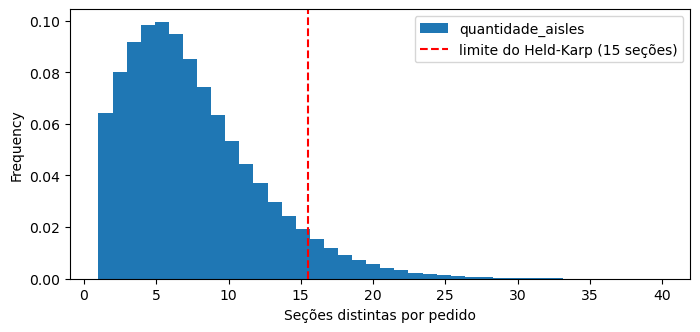

In [4]:
pedidos = oa.groupby("order_id").agg(quantidade_aisles=("aisle_id", "size"), eval_set=("eval_set", "first"))
pedidos.insert(0, "quantidade_itens", itens_por_pedido[pedidos.index])

print(pedidos[["quantidade_itens", "quantidade_aisles"]].describe().round(2))
print("Pedidos com mais de 15 seções:", f"{(pedidos['quantidade_aisles'] > 15).mean():.1%}")

pedidos["quantidade_aisles"].clip(upper=40).plot.hist(bins=40, density=True, figsize=(8, 3.5))
plt.axvline(15.5, color="red", linestyle="--", label="limite do Held-Karp (15 seções)")
plt.xlabel("Seções distintas por pedido")
plt.legend()
plt.show()

## 4. Dia e hora dos pedidos

Distribuição dos pedidos com itens (`prior` e `train`) pelo dia da semana (`order_dow`, de 0 a 6) e pela hora (`order_hour_of_day`). O dataset não informa qual dia é o 0. Para cada dia e hora também se compara o tamanho médio do pedido, que afeta o percurso, e a distribuição dos 100 pedidos de avaliação com a da base.

           pct_pedidos  pct_avaliacao  itens_medios  secoes_medias
order_dow                                                         
0                17.49           20.0         11.16           8.02
1                17.23           22.0         10.19           7.23
2                13.69           13.0          9.56           6.89
3                12.79           12.0          9.34           6.77
4                12.47           10.0          9.45           6.84
5                13.25           17.0          9.89           7.11
6                13.08            6.0         10.75           7.80
Pedidos entre 10h e 16h: 57.4% (avaliação: 53%); entre 0h e 6h: 2.7%
Seções médias por hora: de 7.05 a 7.75


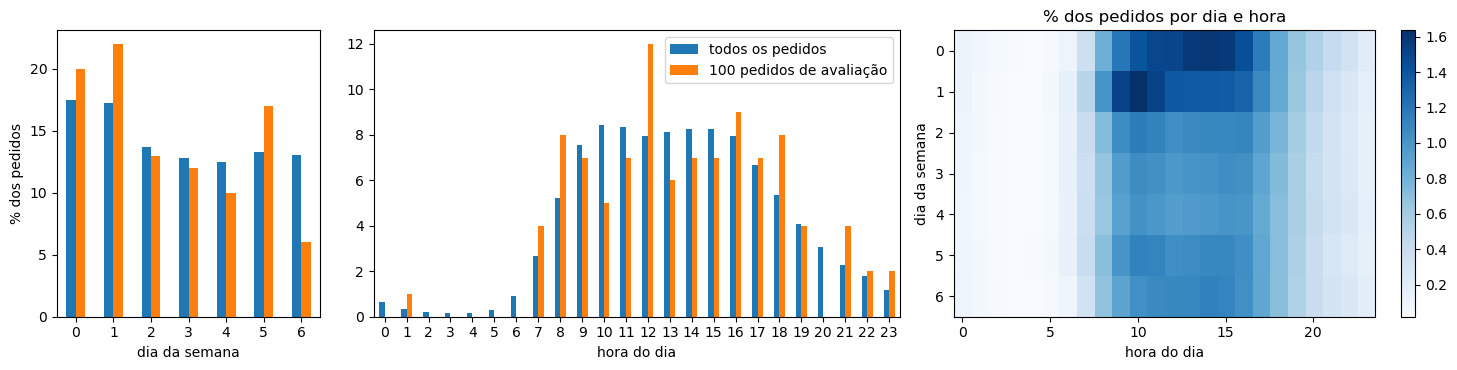

In [5]:
dia_hora = pedidos.join(orders.set_index("order_id")[["order_dow", "order_hour_of_day"]])
avaliacao = pd.read_csv(DADOS / "amostras" / "Pedidos.csv", encoding="utf-8-sig")["order_id"]


def por_periodo(coluna):
    tabela = dia_hora.groupby(coluna).agg(itens_medios=("quantidade_itens", "mean"),
                                          secoes_medias=("quantidade_aisles", "mean"))
    tabela.insert(0, "pct_pedidos", 100 * dia_hora[coluna].value_counts(normalize=True))
    tabela.insert(1, "pct_avaliacao", 100 * dia_hora.loc[avaliacao, coluna].value_counts(normalize=True))
    return tabela.fillna(0).round(2)


por_dia, por_hora = por_periodo("order_dow"), por_periodo("order_hour_of_day")
print(por_dia)
print(f"Pedidos entre 10h e 16h: {por_hora.loc[10:16, 'pct_pedidos'].sum():.1f}% "
      f"(avaliação: {por_hora.loc[10:16, 'pct_avaliacao'].sum():.0f}%); "
      f"entre 0h e 6h: {por_hora.loc[0:6, 'pct_pedidos'].sum():.1f}%")
print(f"Seções médias por hora: de {por_hora['secoes_medias'].min()} a {por_hora['secoes_medias'].max()}")

fig, (dia, hora, mapa) = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 2, 2]})
por_dia[["pct_pedidos", "pct_avaliacao"]].plot.bar(ax=dia, rot=0, legend=False, xlabel="dia da semana",
                                                   ylabel="% dos pedidos")
por_hora[["pct_pedidos", "pct_avaliacao"]].plot.bar(ax=hora, rot=0, xlabel="hora do dia")
hora.legend(["todos os pedidos", "100 pedidos de avaliação"])
calor = mapa.imshow(100 * pd.crosstab(dia_hora["order_dow"], dia_hora["order_hour_of_day"], normalize=True),
                    aspect="auto", cmap="Blues")
mapa.set(xlabel="hora do dia", ylabel="dia da semana", title="% dos pedidos por dia e hora")
fig.colorbar(calor, ax=mapa)
fig.tight_layout()
fig.savefig(DADOS.parent / "figuras" / "pedidos_dia_hora.png", dpi=200)
plt.show()

## 5. Frequência das seções

Em quantos pedidos cada seção aparece. A comparação entre `prior` e `train` mostra se o `train` sozinho representa bem o comportamento geral.

In [6]:
departamento_da_secao = produtos.groupby("aisle_id")["department_id"].first()
n_pedidos = len(pedidos)


def frequencia(pares, chave, nomes):
    contagem = pares.groupby([chave, "eval_set"], observed=True).size().unstack(fill_value=0)
    tabela = contagem.sum(axis=1).rename("quantidade_pedidos").reset_index().merge(nomes, on=chave)
    tabela["pct_pedidos"] = (100 * tabela["quantidade_pedidos"] / n_pedidos).round(2)
    tabela["pedidos_prior"] = tabela[chave].map(contagem["prior"])
    tabela["pedidos_train"] = tabela[chave].map(contagem["train"])
    return tabela.sort_values("quantidade_pedidos", ascending=False, ignore_index=True)


frequencia_aisles = frequencia(oa, "aisle_id", aisles)
frequencia_aisles["department_id"] = frequencia_aisles["aisle_id"].map(departamento_da_secao)

por_conjunto = frequencia_aisles[["pedidos_prior", "pedidos_train"]].rank()
acumulado = frequencia_aisles["quantidade_pedidos"].cumsum() / frequencia_aisles["quantidade_pedidos"].sum()
print("Spearman prior x train:", round(por_conjunto["pedidos_prior"].corr(por_conjunto["pedidos_train"]), 4))
print("Participação das 10, 20 e 50 seções mais pedidas:", [f"{acumulado.iloc[k - 1]:.1%}" for k in (10, 20, 50)])
frequencia_aisles.head(10)

Spearman prior x train: 0.9945
Participação das 10, 20 e 50 seções mais pedidas: ['38.5%', '53.6%', '82.0%']


,aisle_id,quantidade_pedidos,aisle,pct_pedidos,pedidos_prior,pedidos_train,department_id
0,24,1862949,fresh fruits,55.68,1790771,72178,4
1,83,1486803,fresh vegetables,44.43,1427631,59172,4
2,123,1229500,packaged vegetables fruits,36.74,1179243,50257,4
3,120,880330,yogurt,26.31,847081,33249,16
4,84,815345,milk,24.37,785987,29358,16
5,21,769098,packaged cheese,22.99,737899,31199,16
6,115,641024,water seltzer sparkling water,19.16,614081,26943,7
7,91,568087,soy lactosefree,16.98,545714,22373,16
8,107,561234,chips pretzels,16.77,538052,23182,19
9,112,548617,bread,16.40,527129,21488,3


## 6. Coocorrência

`C[i, j]` é o número de pedidos em que `i` e `j` aparecem juntos, e a diagonal é a frequência de cada um. O lift `C[i,j]·N / (f_i·f_j)` compara isso com o esperado se os dois fossem independentes (lift = 1). A matriz é montada por blocos de pedidos para caber na memória.

In [8]:
def coocorrencia(pares, chave, ids, bloco=200_000):
    linha, _ = pd.factorize(pares["order_id"])
    coluna = pd.Index(ids).get_indexer(pares[chave])
    C = np.zeros((len(ids), len(ids)), dtype=np.int64)
    for inicio in range(0, linha.max() + 1, bloco):
        sel = (linha >= inicio) & (linha < inicio + bloco)
        X = np.zeros((bloco, len(ids)), dtype=np.float32)
        X[linha[sel] - inicio, coluna[sel]] = 1
        C += (X.T @ X).astype(np.int64)
    return C, linha.max() + 1


def pares_de_secoes(C, N):
    ids = aisles["aisle_id"].to_numpy()
    nome = aisles.set_index("aisle_id")["aisle"]
    f = np.diag(C)
    i, j = np.triu_indices_from(C, k=1)
    i, j = i[C[i, j] > 0], j[C[i, j] > 0]
    juntos = C[i, j]

    tabela = pd.DataFrame({"aisle_id_1": ids[i], "aisle_id_2": ids[j], "quantidade_pedidos_juntos": juntos,
                           "pedidos_aisle_1": f[i], "pedidos_aisle_2": f[j]})
    tabela["jaccard"] = juntos / (f[i] + f[j] - juntos)
    tabela["lift"] = juntos * N / (f[i] * f[j])
    tabela["aisle_1"] = tabela["aisle_id_1"].map(nome)
    tabela["aisle_2"] = tabela["aisle_id_2"].map(nome)

    return tabela.sort_values("quantidade_pedidos_juntos", ascending=False, ignore_index=True)


C_train, N_train = coocorrencia(oa[oa["eval_set"] == "train"], "aisle_id", aisles["aisle_id"])
C_todos, N_todos = coocorrencia(oa, "aisle_id", aisles["aisle_id"])

coocorrencia_train = pares_de_secoes(C_train, N_train)
coocorrencia_todos = pares_de_secoes(C_todos, N_todos)

print(f"Pares de seções: {len(coocorrencia_train):,} no train e {len(coocorrencia_todos):,} em todos os pedidos")
coocorrencia_todos[coocorrencia_todos["quantidade_pedidos_juntos"] >= 1000].nlargest(10, "lift")

Pares de seções: 8,866 no train e 8,911 em todos os pedidos


,aisle_id_1,aisle_id_2,quantidade_pedidos_juntos,pedidos_aisle_1,pedidos_aisle_2,jaccard,lift,aisle_1,aisle_2
2670,28,62,8013,26212,26174,0.180583,39.080633,red wines,white wines
4826,62,134,2202,26174,10291,0.064268,27.354347,white wines,specialty wines champagnes
4870,28,134,2150,26212,10291,0.062586,26.669657,red wines,specialty wines champagnes
3286,27,28,5502,30877,26212,0.106655,22.746891,beers coolers,red wines
5483,124,134,1535,23705,10291,0.047288,21.054627,spirits,specialty wines champagnes
3501,27,62,4728,30877,26174,0.090362,19.575325,beers coolers,white wines
3966,62,124,3537,26174,23705,0.076324,19.074875,white wines,spirits
3757,27,124,4051,30877,23705,0.080169,18.519271,beers coolers,spirits
5248,27,134,1732,30877,10291,0.043919,18.238618,beers coolers,specialty wines champagnes
4113,28,124,3245,26212,23705,0.069528,17.474763,red wines,spirits


## 7. Exportação

A coocorrência é exportada para todos os pedidos e só para o `train`, porque os pedidos de avaliação estão no `train`: o G2 usa a diferença das duas, que é o `prior`, e assim a avaliação não influencia o layout. Os itens dos 100 pedidos de avaliação saem com `add_to_cart_order`, que define a ordem do carrinho usada como referência.

In [10]:
catalogo = (produtos.groupby("aisle_id")
            .agg(department_id=("department_id", "first"), quantidade_produtos=("product_id", "nunique"))
            .reset_index()
            .merge(aisles, on="aisle_id")
            .merge(departamentos, on="department_id"))
catalogo = catalogo[["aisle_id", "aisle", "department_id", "department", "quantidade_produtos"]]


carrinho = train[train["order_id"].isin(avaliacao)].copy()
carrinho["aisle_id"] = secao_do_produto[carrinho["product_id"]]
carrinho = carrinho[["order_id", "aisle_id", "add_to_cart_order"]].sort_values(["order_id", "add_to_cart_order"])

saidas = {
    CURADOS / "catalogo_aisles_departamentos.csv": catalogo,
    CURADOS / "frequencia_aisles.csv": frequencia_aisles,
    CURADOS / "coocorrencia_aisles_train.csv": coocorrencia_train,
    CURADOS / "coocorrencia_aisles_prior_train.csv": coocorrencia_todos,
    DADOS / "amostras" / "pedidos_avaliacao_carrinho.csv": carrinho,
}
CURADOS.mkdir(exist_ok=True)
for caminho, tabela in saidas.items():
    tabela.to_csv(caminho, index=False)
    print(f"{caminho.name:40s} {len(tabela):>8,} linhas")

catalogo_aisles_departamentos.csv             134 linhas
frequencia_aisles.csv                         134 linhas
coocorrencia_aisles_train.csv               8,866 linhas
coocorrencia_aisles_prior_train.csv         8,911 linhas


pedidos_avaliacao_carrinho.csv              1,079 linhas


## Resumo

- 3.346.083 pedidos com itens (3.214.874 `prior` e 131.209 `train`); os 75.000 `test` não têm itens.
- Nenhum valor ausente, chave duplicada ou produto sem cadastro, e cada seção pertence a um único departamento.
- Um pedido tem, em média, 10,1 itens e 7,3 seções distintas; 6,4% dos pedidos passam de 15 seções.
- O `train` representa bem o `prior` (Spearman de 0,9945 na frequência das seções).
- A demanda é concentrada: as 20 seções mais pedidas somam 53,6% das ocorrências.
- Os dias 0 e 1 concentram 34,7% dos pedidos, que são também os maiores (8,0 e 7,2 seções em média, contra 6,8 a 7,1 nos demais dias). 57,4% dos pedidos são feitos entre 10h e 16h, e o tamanho quase não muda com a hora (7,1 a 7,8 seções). Os 100 pedidos de avaliação seguem esse padrão (53% entre 10h e 16h), com menos pedidos no dia 6 (6% contra 13%).

**Limitações.** O dataset não traz layout físico nem distâncias: `aisle` é uma categoria, e `add_to_cart_order` é a ordem do carrinho online, não a de coleta. Coocorrência e lift medem afinidade de compra, não proximidade.